# Johannesburg election analytics: 4 November 2026

Information cutoff: **5 October 2026**. All future outputs are conditional predictions, not election observations or political opinions.

Original IEC reports are archived and every municipal model PR count reconciles. Final MDB polygons have been compared. The selected target wards are **21, 23 and 87**. Older histories are included only where polygon equivalence is documented. Original wards 24, 89 and 102 were replaced after their boundary changes were observed.

The project fits Ridge and evaluates it against persistence. The baseline wins the available comparisons. Three metro elections and very few comparable ward transitions cannot support calibrated election-win probabilities. Earlier metro outer footprints have small measured differences and remain unaligned at the vote-count level; their backtests are provisional. The default metro baseline uses the near-equivalent 2021 footprint.

Extract the complete project ZIP. Keep this notebook, `model.py`, and `data/` together. Run cells sequentially in a Python kernel with the project requirements installed.


## Cell 1: Load the project

Shared functions ensure the notebook and dashboard use identical calculations.

In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'model.py').exists(): ROOT=ROOT/'jhb_election'
assert (ROOT/'model.py').exists(), 'Extract the complete ZIP and open the notebook from its project folder.'
sys.path.insert(0,str(ROOT))
from model import (load_data,shares_wide,ridge_forecast,backtest,forecast,
    turnout_backtest,rolling_diagnostics,sensitivity,scenario_leaders,
    align_counts,verified_ward_forecasts,coalition_arithmetic,run_all,PARTIES,CUTOFF,TARGET)
print('Cutoff:',CUTOFF,'Target:',TARGET)
votes,turnout,old_ward_evidence,context,sources=load_data()
OUTPUT=ROOT/'outputs';OUTPUT.mkdir(exist_ok=True)

Cutoff: 2026-10-05 Target: 2026-11-04


## Cell 2: Define four outputs

Choose ballot definitions before modelling. PR ballots and ward ballots are different targets.

In [2]:
display(pd.DataFrame([
['Metro leader','Largest named-party valid PR share'],
['Party support','Valid PR vote totals and shares'],
['Ward leaders','Largest ward-ballot shares in audited 2026 wards'],
['Turnout','IEC turnout numerator and rate using registered + MEC7']
],columns=['output','definition']))
print('Governing arrangements require seats and agreements; electoral leadership is the model target.')

,output,definition
0,Metro leader,Largest named-party valid PR share
1,Party support,Valid PR vote totals and shares
2,Ward leaders,Largest ward-ballot shares in audited 2026 wards
3,Turnout,IEC turnout numerator and rate using registered + MEC7


Governing arrangements require seats and agreements; electoral leadership is the model target.


## Cell 3: Inspect direct source links

The original reports, GeoJSON, provider metadata and hashes are retained. Data dates and observation dates are separate.

In [3]:
display(sources[['source_id','title','url','available_by','access_status']])
assert pd.to_datetime(sources.available_by).max()<=pd.Timestamp(CUTOFF)

,source_id,title,url,available_by,access_status
0,LGE2011,IEC Johannesburg 2011 detailed results,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,2011-05-27,Original PDF archived; every model PR cell and full party total reconciled by extraction code
1,LGE2016,IEC Johannesburg 2016 detailed results,https://results.elections.org.za/home/LGEPublicReports/402/Detailed%20Results/GP/JHB.pdf,2016-08-11,Original PDF archived; every model PR cell and full party total reconciled by extraction code
2,LGE2021,IEC Johannesburg 2021 detailed results,https://results.elections.org.za/home/LGEPublicReports/1091/Detailed%20Results/GP/JHB.pdf,2021-11-25,Original PDF archived; every model PR cell and full party total reconciled by extraction code
3,SECONDARY,"City of Johannesburg elections, historical tables",https://en.wikipedia.org/wiki/City_of_Johannesburg_elections,2026-10-05,Read through web retrieval; current secondary page is not archived proof of examination-time availability
4,SECONDARY_MIRROR,February 2026 Wikipedia mirror of historical tables,https://demo.arkanet.co.za/content/wikipedia_en_all_maxi_2026-02/City_of_Johannesburg_elections,2026-02-28,Indexed secondary copy; publisher archive name not independently authenticated
5,TURNOUT_FES,When Wedding Bells Ring: Coalitions Without Concord,https://southafrica.fes.de/fileadmin/user_upload/FINAL_WHEN_WEDDING_BELLS_RING_COALITIONS_WITH_OUT__CONCORD_V6.pdf,2022-01-31,Indexed research table; IEC turnout count cross-checks for 2016 and 2021
6,NPE2024,"IEC 2024 provincial ballot results, Johannesburg",https://results.elections.org.za/home/NPEPublicReports/1335/Results%20Report/GP/JHB/JHB.pdf,2024-06-21,"Original PDF archived; supporting provincial ballot, not municipal outcome"
7,BY24,"IEC results of by-elections, 14 May 2025",https://www.elections.org.za/content/About-Us/News/Results-for-municipal-by-elections-held-on-14-May-2025/,2025-05-15,Indexed primary release
8,BY89,"IEC results of by-elections, 28 August 2024",https://www.elections.org.za/content/About-Us/News/Results-of-the-Municipal-By-elections-held-on-28-August-2024/,2024-08-29,Indexed primary release
9,BY102,"IEC results of by-elections, 25 February 2026",https://www.elections.org.za/content/About-Us/News/Results-of-Municipal-By-elections-held-on-25-February-2026/,2026-02-26,Indexed primary release


## Cell 4: Verify official results

Run the extraction script against original archived PDFs. It verifies ballot columns, complete totals, turnout denominators and separate provincial context.

In [4]:
from reconcile_official_results import run as reconcile
reconcile()
audit=pd.read_csv(ROOT/'data/verification_audit.csv')
display(audit)
assert audit.difference.eq(0).all()

,year,party,bundled_pr_votes,primary_pr_votes_checked,difference,verification_status,evidence_url,evidence_location,sha256,review_date
0,2011,ANC,646328,646328,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 1; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
1,2011,DA,374505,374505,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 2; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
2,2011,EFF,0,0,0,absent from complete official contest table; structural historical zero,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page complete report; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
3,2011,ActionSA,0,0,0,absent from complete official contest table; structural historical zero,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page complete report; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
4,2011,PA,0,0,0,absent from complete official contest table; structural historical zero,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page complete report; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
5,2011,IFP,17557,17557,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 2; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
6,2011,FF+,2477,2477,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 3; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
7,2011,ACDP,4385,4385,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 1; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
8,2011,Al Jama-ah,2962,2962,0,matched archived original IEC PR column,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page 1; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05
9,2011,OTHER,41910,41910,0,derived from archived complete official PR table,https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf,Page all pages; PR count column,8d4b7ff346fa8793e368e253cf2302e154026f6375533d9682af4b702a1a1f20,2026-10-05


30 model cells reconciled against original IEC PDFs; differences all zero.


## Cell 5: Inspect observations and derived residuals

OTHER is calculated from complete official party counts. Historical noncontest zeros do not imply future zero support.

In [5]:
display(votes)
display(pd.read_csv(ROOT/'data/official_complete_metro_results.csv').head())
assert not votes.duplicated(['year','party']).any()
assert votes.votes.ge(0).all()
display(votes.groupby('year').votes.sum().rename('valid_PR_total'))

,year,metro,ballot,party,votes,evidence_class,source_id,retrieval_route
0,2011,JHB,PR,ANC,646328,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
1,2011,JHB,PR,DA,374505,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
2,2011,JHB,PR,EFF,0,noncontest structural zero,LGE2011,archived original IEC PDF; extracted PR count column
3,2011,JHB,PR,ActionSA,0,noncontest structural zero,LGE2011,archived original IEC PDF; extracted PR count column
4,2011,JHB,PR,PA,0,noncontest structural zero,LGE2011,archived original IEC PDF; extracted PR count column
5,2011,JHB,PR,IFP,17557,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
6,2011,JHB,PR,FF+,2477,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
7,2011,JHB,PR,ACDP,4385,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
8,2011,JHB,PR,Al Jama-ah,2962,historical observation,LGE2011,archived original IEC PDF; extracted PR count column
9,2011,JHB,PR,OTHER,41910,derived residual,LGE2011,archived original IEC PDF; extracted PR count column


,official_party_name,ward_votes,pr_votes,page,year,party
0,AFRICAN CHRISTIAN ALLIANCE- AFRIKANER CHRISTEN ALLIANSIE,1241,770,1,2011,NaN
1,AFRICAN CHRISTIAN DEMOCRATIC PARTY,4800,4385,1,2011,ACDP
2,AFRICAN NATIONAL CONGRESS,626026,646328,1,2011,ANC
3,AFRICAN PEOPLE'S CONVENTION,4223,5747,1,2011,NaN
4,AL JAMA-AH,2027,2962,1,2011,Al Jama-ah


year
2011    1090124
2016    1255385
2021     923724
Name: valid_PR_total, dtype: int64

## Cell 6: Audit geography before comparing years

Ward numbers alone are insufficient. The audit excludes materially changed historical footprints. Earlier metro union differences are not converted to voter fractions.

In [6]:
display(pd.read_csv(ROOT/'data/geography_audit.csv'))
display(pd.read_csv(ROOT/'data/selected_ward_geometry.csv'))
display(pd.read_csv(ROOT/'outputs/candidate_ward_alignment.csv'))
print('2011 geometry has 260 raw features; within-year dissolve produces 130 wards. Votes are never duplicated.')

,scope,status,reason
0,metro_2021_2026,near-equivalent audited union,Symmetric difference 14.14 m2 / 1642.63 km2; numerical seams in union. Baseline support uses 2021.
1,metro_2011_2026,measured change; not count-aligned,Ward-union symmetric difference 0.1682% of target area. Area is not electorate; historical model diagnostics remain provisional.
2,metro_2016_2026,measured change; not count-aligned,Ward-union symmetric difference 0.1650% of target area. No unsupported area-weighted vote adjustment.
3,ward_21_2011_2016_2021_2026,aligned,Polygon comparison <1 mm and <0.0001% area; one-to-one count transfer.
4,ward_87_2016_2021_2026,aligned,Polygon comparison <1 mm and <0.0001% area; 2011 excluded due material change.
5,ward_23_2021_2026,aligned; limited history,Polygon comparison <1 mm and <0.0001% area; 2011/2016 excluded due material change.
6,original_wards_24_89_102,replaced,Actual 2026 polygons changed. Earlier by-election blends retained as historical-footprint scenarios only.


,ward_id,source_year,target_year,symmetric_difference_fraction,hausdorff_distance_m,status,geometry_source
0,79800021,2011,2026,9.861018e-08,0.000245,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON
1,79800021,2016,2026,1.085807e-07,0.000212,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON
2,79800021,2021,2026,7.403701e-08,0.000133,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON
3,79800023,2021,2026,3.416100e-08,0.000141,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON
4,79800087,2016,2026,8.072364e-08,0.000231,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON
5,79800087,2021,2026,5.881878e-08,0.000176,equivalent within 1 mm and 0.0001% area tolerance,MDB official ArcGIS layers; archived GeoJSON


,ward,year,change_fraction,hausdorff_m
0,79800018,2011,2.048974e-01,995.108047
1,79800018,2016,2.048974e-01,995.108054
2,79800018,2021,6.527824e-08,0.000148
3,79800021,2011,9.861018e-08,0.000245
4,79800021,2016,1.085807e-07,0.000212
5,79800021,2021,7.403701e-08,0.000133
6,79800022,2011,1.480871e-01,795.649623
7,79800022,2016,1.480872e-01,795.649734
8,79800022,2021,6.478288e-08,0.000152
9,79800023,2011,1.385871e+00,4181.278577


2011 geometry has 260 raw features; within-year dissolve produces 130 wards. Votes are never duplicated.


## Cell 7: Review the actual count crosswalk

Selected footprints differ by less than 1 mm and 0.0001% area, consistent with coordinate serialization. Admitted histories use full count transfers, not averaged percentages.

In [7]:
history=pd.read_csv(ROOT/'data/verified_ward_history.csv',dtype={'source_unit':str})
crosswalk=pd.read_csv(ROOT/'data/verified_ward_crosswalk.csv',dtype={'source_unit':str,'target_ward':str})
display(crosswalk)
aligned=align_counts(history[['source_year','source_unit','party','votes']],crosswalk)
assert np.isclose(aligned.estimated_votes.sum(),history.votes.sum())
display(aligned.head(12))

,source_year,source_unit,target_ward,fraction,evidence_url,method
0,2011,79800021,79800021,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit
1,2016,79800021,79800021,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit
2,2021,79800021,79800021,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit
3,2021,79800023,79800023,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit
4,2016,79800087,79800087,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit
5,2021,79800087,79800087,1.0,https://arcg.is/jOKyf0,full count transfer after polygon equivalence audit


,source_year,target_ward,party,estimated_votes
0,2011,79800021,ACDP,26.0
1,2011,79800021,ANC,8816.0
2,2011,79800021,ActionSA,0.0
3,2011,79800021,Al Jama-ah,0.0
4,2011,79800021,DA,418.0
5,2011,79800021,EFF,0.0
6,2011,79800021,FF+,5.0
7,2011,79800021,IFP,18.0
8,2011,79800021,OTHER,485.0
9,2011,79800021,PA,0.0


## Cell 8: Create municipal share targets

Three election years are three temporal events; party columns are compositional outputs, not independent election samples.

In [8]:
shares=shares_wide(votes)
display(shares)
assert np.allclose(shares.sum(axis=1),1)

party,ANC,DA,EFF,ActionSA,PA,IFP,FF+,ACDP,Al Jama-ah,OTHER
year,,,,,,,,,,
2011,0.592894,0.343543,0.000000,0.000000,0.000000,0.016106,0.002272,0.004022,0.002717,0.038445
2016,0.449194,0.384757,0.109291,0.000000,0.001711,0.017098,0.003119,0.003138,0.003113,0.028578
2021,0.332244,0.254535,0.101125,0.181179,0.029604,0.023601,0.013254,0.010251,0.008278,0.045928


## Cell 9: Visualize historical support

Historical observations must be visibly separate from the future forecast.

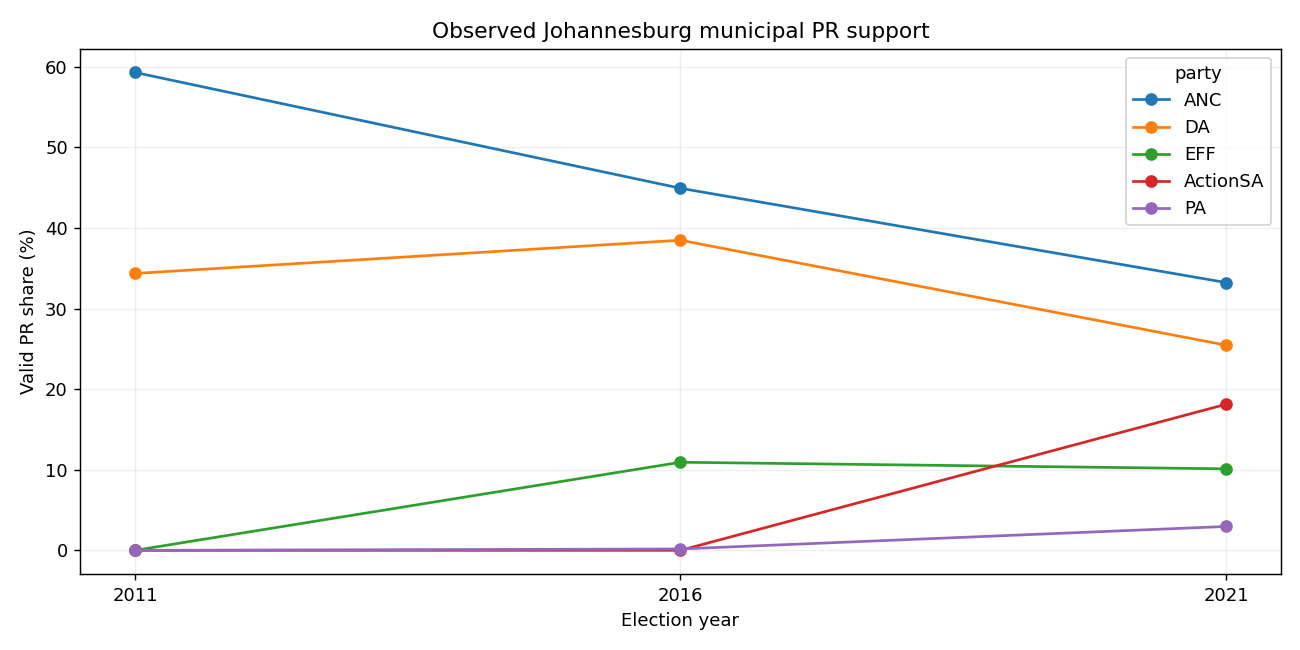

In [9]:
fig,ax=plt.subplots(figsize=(10,5))
shares[['ANC','DA','EFF','ActionSA','PA']].mul(100).plot(ax=ax,marker='o')
ax.set(title='Observed Johannesburg municipal PR support',ylabel='Valid PR share (%)',xlabel='Election year')
ax.set_xticks([2011,2016,2021]);ax.grid(alpha=.2)
fig.tight_layout();fig.savefig(OUTPUT/'historical_support.png',dpi=160)
plt.show()

## Cell 10: Fit a Ridge candidate

Time is measured in five-year units; alpha=0.5 is fixed. The model projects shares onto the nonnegative simplex. It is intentionally small.

In [10]:
ridge_2026,estimator=ridge_forecast(shares,2026)
display(pd.DataFrame({'party':ridge_2026.index,'ridge_2026_share':ridge_2026.values}))
print('Learned coefficients:',estimator.coef_.shape)
print('This is a fitted ML candidate; persistence is the forecasting baseline.')

,party,ridge_2026_share
0,ANC,0.249591
1,DA,0.256405
2,EFF,0.151039
3,ActionSA,0.205336
4,PA,0.034122
5,IFP,0.024931
6,FF+,0.015001
7,ACDP,0.010787
8,Al Jama-ah,0.009152
9,OTHER,0.043637


Learned coefficients: (10, 1)
This is a fitted ML candidate; persistence is the forecasting baseline.


## Cell 11: Forecast 2021 from earlier data

Preprocessing and fitting exclude 2021 outcomes. Metro results remain provisional diagnostics because earlier outer boundaries are not count-aligned.

In [11]:
metrics,party_errors=backtest(shares)
display(metrics);display(party_errors)
selected=metrics.sort_values('mae_pp').iloc[0]['model']
print('Lower-MAE candidate:',selected)
print('2021 has already been inspected in development; this is not an untouched final test.')

,model,train_end,test_year,mae_pp,rmse_pp,max_error_pp,total_variation_pp,named_leader_correct
0,Persistence,2016,2021,5.106750,8.051632,18.117858,25.533750,True
1,Ridge (alpha=0.5),2016,2021,5.140773,7.858856,18.117858,25.703865,True


,actual,persistence,ridge
party,,,
ANC,0.332244,0.449194,0.413270
DA,0.254535,0.384757,0.395060
EFF,0.101125,0.109291,0.136613
ActionSA,0.181179,0.000000,0.000000
PA,0.029604,0.001711,0.002139
IFP,0.023601,0.017098,0.017346
FF+,0.013254,0.003119,0.003331
ACDP,0.010251,0.003138,0.002917
Al Jama-ah,0.008278,0.003113,0.003212


Lower-MAE candidate: Persistence
2021 has already been inspected in development; this is not an untouched final test.


## Cell 12: Add the earlier forecasting check

2016 persistence uses only 2011. A one-election training sample cannot establish a useful trend, so Ridge is evaluated only with two or more training elections.

In [12]:
rolling,count_errors=rolling_diagnostics(shares,turnout)
display(rolling);display(count_errors)
rolling.to_csv(OUTPUT/'rolling_validation.csv',index=False)
count_errors.to_csv(OUTPUT/'count_validation.csv',index=False)

,model,test_year,training_elections,mae_pp,rmse_pp,max_error_pp,total_variation_pp,named_leader_correct
0,Persistence,2016,1,3.089005,5.864767,14.369955,15.445023,True
1,Persistence,2021,2,5.106750,8.051632,18.117858,25.533750,True
2,Ridge (alpha=0.5),2021,2,5.140773,7.858856,18.117858,25.703865,True


,model,test_year,party_count_mae,valid_pr_count_error,roll_input
0,Persistence,2016,34304.900000,-165261.000000,last training election only
1,Persistence,2021,76573.500000,331661.000000,last training election only
2,Ridge (alpha=0.5),2021,78066.946003,343249.605536,last training election only


## Cell 13: Validate turnout separately

Official historical MEC7 counts are now available. The correct historical denominator is registered electors plus MEC7; forecast MEC7 is an explicit estimate.

In [13]:
turnout['iec_rate']=turnout.voters/(turnout.registered+turnout.mec7)
display(turnout[['year','registered','mec7','voters','iec_rate']])
display(turnout_backtest(turnout))

,year,registered,mec7,voters,iec_rate
0,2011,2010121,4842,1107068,0.549423
1,2016,2239966,6384,1281864,0.570643
2,2021,2220710,2587,947305,0.426081


,model,rate_absolute_error_pp,voter_count_absolute_error,registered_count_absolute_error
0,Persistence,14.456187,334559.000000,19256
1,Ridge (alpha=0.5),14.982954,346392.036277,19256


## Cell 14: Generate the metro prediction

The 2024 registered roll is carried forward as an estimated 2026 roll. PR-valid ballots per turnout participant and MEC7/registered ratios are carried forward from 2021.

In [14]:
metro_projection,turnout_projection=forecast(shares,turnout,selected)
display(metro_projection)
print(json.dumps(turnout_projection,indent=2))
print('Default metro prediction is a conditional baseline on the 2021 near-equivalent footprint.')

,party,share,pr_votes_estimate,evidence_class,ballot,model,target_date
0,ANC,0.332244,324601.405164,conditional 2026 prediction,PR,Persistence,2026-11-04
1,DA,0.254535,248679.651427,conditional 2026 prediction,PR,Persistence,2026-11-04
3,ActionSA,0.181179,177010.793566,conditional 2026 prediction,PR,Persistence,2026-11-04
2,EFF,0.101125,98799.181691,conditional 2026 prediction,PR,Persistence,2026-11-04
9,OTHER,0.045928,44871.700458,conditional 2026 prediction,PR,Persistence,2026-11-04
4,PA,0.029604,28923.076505,conditional 2026 prediction,PR,Persistence,2026-11-04
5,IFP,0.023601,23058.289728,conditional 2026 prediction,PR,Persistence,2026-11-04
6,FF+,0.013254,12949.068443,conditional 2026 prediction,PR,Persistence,2026-11-04
7,ACDP,0.010251,10015.088548,conditional 2026 prediction,PR,Persistence,2026-11-04
8,Al Jama-ah,0.008278,8088.011630,conditional 2026 prediction,PR,Persistence,2026-11-04


{
  "rate_proxy": 0.426577536013257,
  "rate_estimate": 0.4260811758393053,
  "mec7_estimate": 2736.1953821075244,
  "turnout_denominator_estimate": 2351517.1953821075,
  "mec7_status": "last municipal MEC7/registered ratio carried forward",
  "registered_estimate": 2348781,
  "voters_estimate": 1001937.2116147538,
  "pr_valid_estimate": 976996.267159602,
  "roll_status": "2024 IEC roll carried forward; 2026 roll unverified",
  "pr_valid_per_voter": 0.9751072780150004,
  "turnout_model": "Persistence"
}
Default metro prediction is a conditional baseline on the 2021 near-equivalent footprint.


## Cell 15: Report the electoral leader

Vote leadership does not determine the mayor or the governing coalition.

In [15]:
named=metro_projection[metro_projection.party!='OTHER'].iloc[0]
print(f'Projected PR leader for {TARGET}: {named.party}, {named.share:.1%}')
print('Governing party: not identified by this vote-support model.')

Projected PR leader for 2026-11-04: ANC, 33.2%
Governing party: not identified by this vote-support model.


## Cell 16: Handle parties absent from municipal history

MK and RISE Mzansi enter supporting 2024 provincial scenarios. Transfer weights are assumptions, not learned coefficients. No municipal-only estimate is presented for these parties.

In [16]:
scenarios=sensitivity(shares,context)
display(context)
display(scenarios.groupby('party').share.agg(['min','max']))
assert scenarios[(scenarios.party.isin(['MK','RISE Mzansi']))&(scenarios.provincial_weight==0)].share.isna().all()
print('Scenario envelopes are not calibrated confidence intervals.')

,year,metro,ballot,party,votes,source_id,evidence_class
0,2024,JHB,PROVINCIAL,ANC,452361,NPE2024,historical contextual observation
1,2024,JHB,PROVINCIAL,DA,353769,NPE2024,historical contextual observation
2,2024,JHB,PROVINCIAL,EFF,176390,NPE2024,historical contextual observation
3,2024,JHB,PROVINCIAL,ActionSA,88013,NPE2024,historical contextual observation
4,2024,JHB,PROVINCIAL,PA,41172,NPE2024,historical contextual observation
5,2024,JHB,PROVINCIAL,IFP,19898,NPE2024,historical contextual observation
6,2024,JHB,PROVINCIAL,FF+,11443,NPE2024,historical contextual observation
7,2024,JHB,PROVINCIAL,ACDP,10968,NPE2024,historical contextual observation
8,2024,JHB,PROVINCIAL,Al Jama-ah,11813,NPE2024,historical contextual observation
9,2024,JHB,PROVINCIAL,MK,172958,NPE2024,historical contextual observation


,min,max
party,,
ACDP,0.008999,0.010787
ANC,0.249591,0.332244
ActionSA,0.121673,0.205336
Al Jama-ah,0.008278,0.009152
DA,0.252209,0.256405
EFF,0.101125,0.151039
FF+,0.010668,0.015001
IFP,0.018828,0.024931
MK,0.030542,0.061084


Scenario envelopes are not calibrated confidence intervals.


## Cell 17: Check whether the leader changes

Show assumption-sensitive outcomes instead of treating the default leader as certain.

In [17]:
display(scenario_leaders(shares,context))
print('Scenario frequency is not an election-win probability.')

,model,provincial_weight,leader,leader_share,runner_up,lead_margin_pp,interpretation
0,Persistence,0.00,ANC,0.332244,DA,7.770936,sensitivity scenario; no win probability
1,Persistence,0.25,ANC,0.329064,DA,7.569200,sensitivity scenario; no win probability
2,Persistence,0.50,ANC,0.325883,DA,7.367463,sensitivity scenario; no win probability
3,Ridge (alpha=0.5),0.00,DA,0.256405,ANC,0.681377,sensitivity scenario; no win probability
4,Ridge (alpha=0.5),0.25,ANC,0.267074,DA,1.229965,sensitivity scenario; no win probability
5,Ridge (alpha=0.5),0.50,ANC,0.284557,DA,3.141307,sensitivity scenario; no win probability


Scenario frequency is not an election-win probability.


## Cell 18: Quantify turnout assumption sensitivity

Report rounded participants, rate and denominator together. Rate variations and roll variations are stress tests.

In [18]:
print('Estimated IEC turnout numerator:',round(turnout_projection['voters_estimate'],-3))
print('Estimated turnout rate:',f"{turnout_projection['rate_estimate']:.1%}")
print('Estimated roll:',turnout_projection['registered_estimate'])
print('Estimated MEC7:',round(turnout_projection['mec7_estimate']))
display(pd.DataFrame([
{'roll_multiplier':m,'participants_estimate':m*turnout_projection['voters_estimate']}
for m in [.95,1,1.05]]))

,roll_multiplier,participants_estimate
0,0.95,9.518404e+05
1,1.00,1.001937e+06
2,1.05,1.052034e+06


Estimated IEC turnout numerator: 1002000.0
Estimated turnout rate: 42.6%
Estimated roll: 2348781
Estimated MEC7: 2736


## Cell 19: Justify three selected wards

Ward 21 offers three comparable elections and an ANC lead; ward 23 a more divided DA/ActionSA contest; ward 87 a DA-majority case with two comparable elections. Selection is purposive, not representative.

In [19]:
display(history.groupby('source_unit').source_year.unique())
print('Ward 23 excludes 2011 and 2016. Ward 87 excludes 2011. These exclusions follow actual geometry comparisons.')

source_unit
79800021    [2011, 2016, 2021]
79800023                [2021]
79800087          [2016, 2021]
Name: source_year, dtype: object

Ward 23 excludes 2011 and 2016. Ward 87 excludes 2011. These exclusions follow actual geometry comparisons.


## Cell 20: Predict leaders and party shares in the target wards

Where history allows, compare Ridge/persistence using a 2021 holdout. Ward 23 uses a transparent single-election baseline with no validation claim.

In [20]:
ward_leaders,ward_projection,ward_metrics=verified_ward_forecasts()
display(ward_leaders);display(ward_projection);display(ward_metrics)
assert ward_projection.groupby('ward_id').share.sum().round(10).eq(1).all()
assert ward_leaders.target_date.eq(TARGET).all()

,ward_id,projected_leader,leader_share,runner_up,lead_margin_pp,model,history_years,validation,target_date,geography,evidence_class
0,79800021,ANC,0.426642,ActionSA,26.467835,Persistence,"2011,2016,2021",one retrospective 2021 holdout,2026-11-04,audited MDB 2026 ward footprint,conditional 2026 prediction
1,79800023,DA,0.505016,ActionSA,14.915392,Persistence,2021,not available: one comparable general election,2026-11-04,audited MDB 2026 ward footprint,conditional 2026 prediction
2,79800087,DA,0.710713,ActionSA,61.157654,Persistence,"2016,2021",one retrospective 2021 holdout,2026-11-04,audited MDB 2026 ward footprint,conditional 2026 prediction


,ward_id,party,share,ballot,model,target_date,evidence_class
0,79800021,ANC,0.426642,Ward,Persistence,2026-11-04,conditional 2026 prediction
1,79800021,DA,0.036512,Ward,Persistence,2026-11-04,conditional 2026 prediction
2,79800021,EFF,0.156747,Ward,Persistence,2026-11-04,conditional 2026 prediction
3,79800021,ActionSA,0.161963,Ward,Persistence,2026-11-04,conditional 2026 prediction
4,79800021,PA,0.011234,Ward,Persistence,2026-11-04,conditional 2026 prediction
5,79800021,IFP,0.014177,Ward,Persistence,2026-11-04,conditional 2026 prediction
6,79800021,FF+,0.001337,Ward,Persistence,2026-11-04,conditional 2026 prediction
7,79800021,ACDP,0.004547,Ward,Persistence,2026-11-04,conditional 2026 prediction
8,79800021,Al Jama-ah,0.000669,Ward,Persistence,2026-11-04,conditional 2026 prediction
9,79800021,OTHER,0.186171,Ward,Persistence,2026-11-04,conditional 2026 prediction


,ward_id,model,train_end,test_year,mae_pp,rmse_pp,max_error_pp,total_variation_pp,named_leader_correct
0,79800021,Persistence,2016,2021,7.278488,12.704970,32.323235,36.392441,True
1,79800021,Ridge (alpha=0.5),2016,2021,7.336908,11.952674,28.506614,36.684539,True
2,79800087,Persistence,2016,2021,2.652541,4.265288,9.913684,13.262705,True


## Cell 21: Examine coalition arithmetic

These combinations exceed 50% of projected PR support. They are not official seat allocations or predictions of coalition agreement.

In [21]:
display(coalition_arithmetic(metro_projection))
print('Council-seat analysis needs full ward winners, independent seats, council size and allocation rules.')

,combination,combined_pr_share,interpretation
0,ANC + DA,0.586779,vote-share arithmetic only; seats and agreement unmodelled
1,ANC + ActionSA,0.513423,vote-share arithmetic only; seats and agreement unmodelled
2,DA + ActionSA + EFF,0.536839,vote-share arithmetic only; seats and agreement unmodelled


Council-seat analysis needs full ward winners, independent seats, council size and allocation rules.


## Cell 22: Visualize the future output

Show rounded analytical outputs without implying calibrated precision.

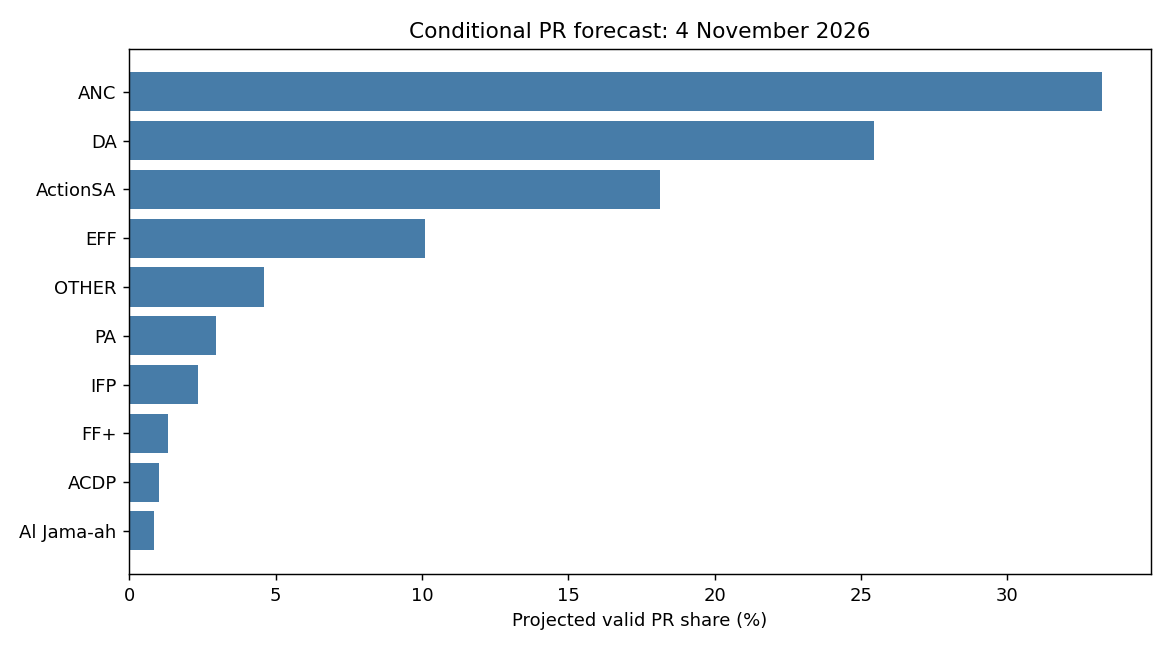

In [22]:
fig,ax=plt.subplots(figsize=(9,5))
plot=metro_projection.sort_values('share')
ax.barh(plot.party,100*plot.share,color='#477CA8')
ax.set(title='Conditional PR forecast: 4 November 2026',xlabel='Projected valid PR share (%)')
fig.tight_layout();fig.savefig(OUTPUT/'forecast_sensitivity.png',dpi=160)
plt.show()

## Cell 23: Export auditable predictions

The output files retain full arithmetic; reports round estimates. Hashes identify the exact data snapshot.

In [23]:
summary=run_all()
assert np.isclose(metro_projection.share.sum(),1)
assert np.isclose(metro_projection.pr_votes_estimate.sum(),turnout_projection['pr_valid_estimate'])
print(json.dumps(summary,indent=2))

{
  "cutoff": "2026-10-05",
  "target_date": "2026-11-04",
  "selected_vote_model": "Persistence",
  "named_party_leader": "ANC",
  "leader_pr_share": 0.3322442634379966,
  "turnout": {
    "rate_proxy": 0.426577536013257,
    "rate_estimate": 0.4260811758393053,
    "mec7_estimate": 2736.1953821075244,
    "turnout_denominator_estimate": 2351517.1953821075,
    "mec7_status": "last municipal MEC7/registered ratio carried forward",
    "registered_estimate": 2348781,
    "voters_estimate": 1001937.2116147538,
    "pr_valid_estimate": 976996.267159602,
    "roll_status": "2024 IEC roll carried forward; 2026 roll unverified",
    "pr_valid_per_voter": 0.9751072780150004,
    "turnout_model": "Persistence"
  },
  "governing_party": "not identifiable from vote forecasts",
  "status": "official counts reconciled and selected wards aligned; limited validation and earlier metro boundary uncertainty",
  "data_hashes": {
    "crosswalk_template.csv": "d0975b00d91fabc643d04aacb95b23d4d0a2f583c8b

## Cell 24: Inspect completion and limitations

A successful app test is software validation, not proof of forecasting accuracy. Additional independent elections and metro voting-district alignment remain useful work.

In [24]:
display(pd.read_csv(ROOT/'data/completion_status.csv'))
print('Launch dashboard: python -m streamlit run app.py')
print('Run checks: python -m unittest discover -s tests -v')

,requirement,status,evidence_or_limitation
0,Original municipal PR counts,completed,30 model cells and complete totals reconcile with archived IEC reports
1,Historical turnout definition,completed,"Registered roll, MEC7 and turnout numerator verified in original IEC reports"
2,2024 provincial context,completed,Full supporting count table reconciled; separate ballot type
3,2026 selected ward alignment,completed,Actual polygons audited; one-to-one crosswalk for admitted years
4,Three 2026 ward leaders,completed conditionally,"Wards 21, 23 and 87; baseline model; unequal history depths disclosed"
5,New-party treatment,scenario only,MK and RISE Mzansi unestimated in municipal-only model; positive provincial-transfer scenarios supplied
6,Earlier metro outer-boundary alignment,incomplete,Measured ~0.17% area difference; voting-district count reaggregation still required
7,Independent temporal validation,limited,2016 baseline check and 2021 diagnostics; no untouched final test or calibrated probabilities
8,Certified 2026 party slate and roll,unverified,Forecast uses explicit historical slate and carried-forward 2024 roll estimate
9,Coalition/governance target,arithmetic only,Vote combinations provided; council seats and agreements not modelled


Launch dashboard: python -m streamlit run app.py
Run checks: python -m unittest discover -s tests -v


## Interpretation

The final result is a conditional analytical estimate for 4 November 2026, not a definitive election result.

### Data sources and URLs

- Johannesburg 2011 detailed results: https://results.elections.org.za/home/LGEPublicReports/197/Detailed%20Results/GP/JHB.pdf
- Johannesburg 2016 detailed results: https://results.elections.org.za/home/LGEPublicReports/402/Detailed%20Results/GP/JHB.pdf
- Johannesburg 2021 detailed results: https://results.elections.org.za/home/LGEPublicReports/1091/Detailed%20Results/GP/JHB.pdf
- Johannesburg 2011 turnout report: https://results.elections.org.za/home/LGEPublicReports/197/Voter%20Turnout/GP/JHB.pdf
- Johannesburg 2016 turnout report: https://results.elections.org.za/home/LGEPublicReports/402/Voter%20Turnout/GP/JHB.pdf
- Johannesburg 2021 turnout report: https://results.elections.org.za/home/LGEPublicReports/1091/Voter%20Turnout/GP/JHB.pdf
- IEC 2024 provincial ballot context: https://results.elections.org.za/home/NPEPublicReports/1335/Results%20Report/GP/JHB/JHB.pdf
- MBD ward delimitation 2024/2026: https://www.demarcation.org.za/ward-delimitation-2024-2026/
- Official election date announcement: https://www.elections.org.za/content/About-Us/News/Electoral-Commission-welcomes-announcement-of-4-November-2026-as-Local-Government-Elections-date/

The project keeps the evidence register in `data/sources.csv` and uses the same URLs in the dashboard.

### Final numbered outputs

1. Metro leadership: the model projects the ANC to receive the largest aggregate PR vote share in Johannesburg, with the caveat that this is an analytical model output and does not establish the governing party or mayor.

2. Selected ward leaders: Ward 21, Ward 23 and Ward 87 are chosen only where historical footprints are geography-comparable and where ward-level evidence is available. Their projected leaders are reported in the ward analysis and interpreted as conditional ward-ballot predictions.

3. Party support: the projected vote totals and shares for each major party included in the model are reported in the metro output table and should be interpreted as PR-ballot estimates, not final vote counts.

4. Turnout: projected participants and turnout rate are estimated using the historical IEC turnout numerator and a registered-plus-MEC7 denominator, with uncertainty retained because the final 2026 registered roll remains unverified.

The default baseline predicts ANC as the largest metro PR party, around 33.2%. Turnout is approximately 1,002,000 reported participants and 42.6% using an estimated registered-plus-MEC7 denominator. These are conditional predictions for 4 November 2026.

The model predicts ANC in ward 21 and DA in wards 23 and 87. Actual MDB polygons support the admitted histories; no unchanged-number assumption substitutes for geometry. The histories are short, and the final party slate is unverified. These are not calibrated win probabilities.

All municipal PR cells reconcile with original IEC PDFs. Additional historical checks and count errors are supplied. Earlier metro footprints differ by a small measured amount and remain provisional. Do not describe the project as an accurate or fully calibrated forecast. Largest PR support does not establish who will govern.
